In [4]:

import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("CASP.csv")

print("Original Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

df.columns = df.columns.str.strip()
df.drop_duplicates(inplace=True)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

print("\nCleaned Dataset:")
print(df.head())
print("\nCleaned Dataset Shape:", df.shape)
print("\nMissing Values After Cleaning:\n", df.isnull().sum())

df.to_csv("cleaned_CASP.csv", index=False)

print("\nCleaned dataset saved successfully!")

files.download("cleaned_CASP.csv")

Saving CASP.csv to CASP.csv
Original Dataset:
     RMSD        F1       F2       F3        F4            F5        F6  \
0  17.284  13558.30  4305.35  0.31754  162.1730  1.872791e+06  215.3590   
1   6.021   6191.96  1623.16  0.26213   53.3894  8.034467e+05   87.2024   
2   9.275   7725.98  1726.28  0.22343   67.2887  1.075648e+06   81.7913   
3  15.851   8424.58  2368.25  0.28111   67.8325  1.210472e+06  109.4390   
4   7.962   7460.84  1736.94  0.23280   52.4123  1.021020e+06   94.5234   

        F7   F8       F9  
0  4287.87  102  27.0302  
1  3328.91   39  38.5468  
2  2981.04   29  38.8119  
3  3248.22   70  39.0651  
4  2814.42   41  39.9147  

Dataset Shape: (45730, 10)

Missing Values:
 RMSD    0
F1      0
F2      0
F3      0
F4      0
F5      0
F6      0
F7      0
F8      0
F9      0
dtype: int64

Duplicate Rows: 1711

Cleaned Dataset:
     RMSD        F1       F2       F3        F4            F5        F6  \
0  17.284  13558.30  4305.35  0.31754  162.1730  1.872791e+06  215.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
print(df.shape)
print(df.head())

(44019, 10)
     RMSD        F1       F2       F3        F4            F5        F6  \
0  17.284  13558.30  4305.35  0.31754  162.1730  1.872791e+06  215.3590   
1   6.021   6191.96  1623.16  0.26213   53.3894  8.034467e+05   87.2024   
2   9.275   7725.98  1726.28  0.22343   67.2887  1.075648e+06   81.7913   
3  15.851   8424.58  2368.25  0.28111   67.8325  1.210472e+06  109.4390   
4   7.962   7460.84  1736.94  0.23280   52.4123  1.021020e+06   94.5234   

        F7   F8       F9  
0  4287.87  102  27.0302  
1  3328.91   39  38.5468  
2  2981.04   29  38.8119  
3  3248.22   70  39.0651  
4  2814.42   41  39.9147  


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df.drop("RMSD", axis=1)
y = df["RMSD"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data prepared successfully!")

Data prepared successfully!


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import LinearSVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X = df.drop("RMSD", axis=1)
y = df["RMSD"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (35215, 9)
Testing data: (8804, 9)


In [10]:

def visualize_regression(model, name):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, predictions, alpha=0.45, s=15)

    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())

    plt.plot([low, high], [low, high], "r--")
    plt.xlabel("Actual RMSD")
    plt.ylabel("Predicted RMSD")
    plt.title(f"{name}\nR2 Score: {r2:.3f} | RMSE: {rmse:.3f}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(name)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", rmse)
    print("R2 Score:", r2)

    return predictions

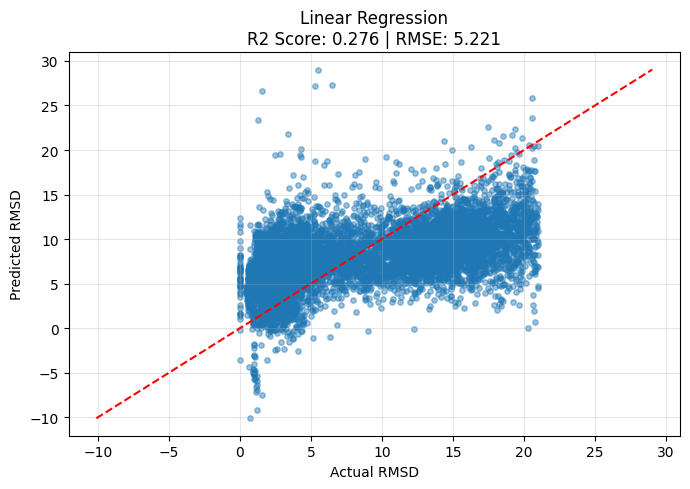

Linear Regression
MAE: 4.383114818246958
RMSE: 5.22146356178483
R2 Score: 0.2756598541300114


In [11]:

model_lr = LinearRegression()

pred_lr = visualize_regression(
    model_lr, "Linear Regression"
)

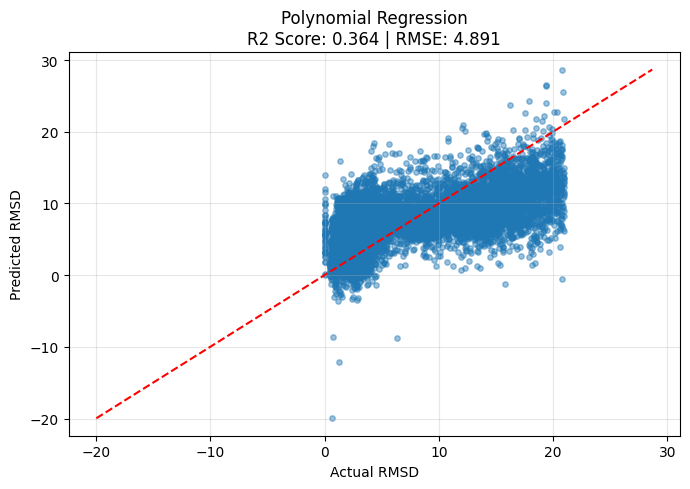

Polynomial Regression
MAE: 4.048944929584069
RMSE: 4.891397815749532
R2 Score: 0.3643412587196354


In [12]:

model_poly = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

pred_poly = visualize_regression(
    model_poly, "Polynomial Regression"
)

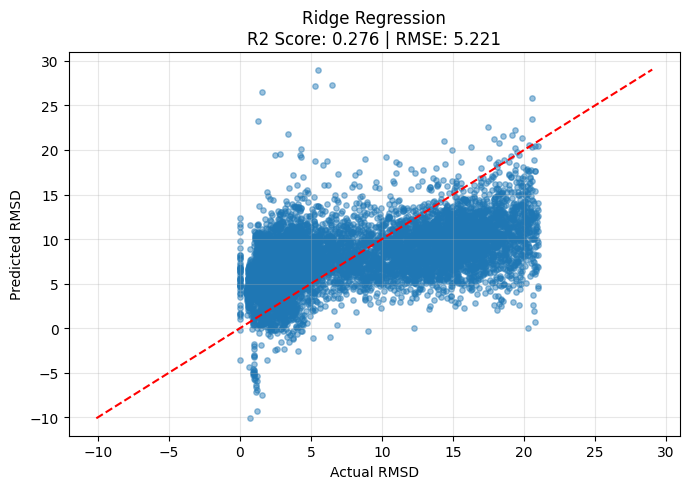

Ridge Regression
MAE: 4.383302593935398
RMSE: 5.221488508188616
R2 Score: 0.2756529328043297


In [13]:

model_ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

pred_ridge = visualize_regression(
    model_ridge, "Ridge Regression"
)

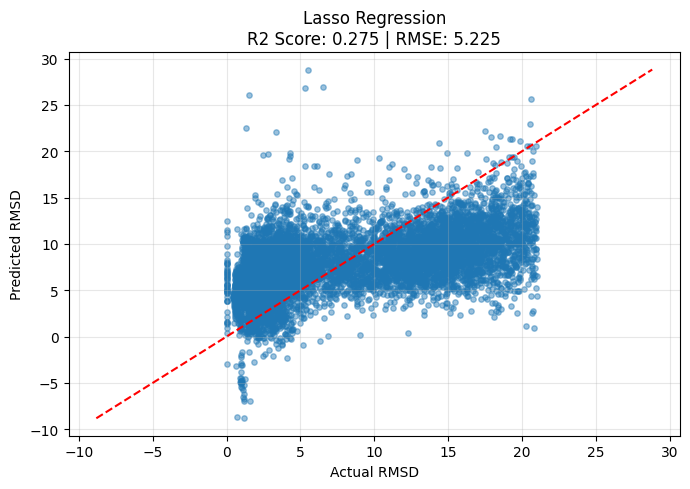

Lasso Regression
MAE: 4.3923005568374975
RMSE: 5.224578897919884
R2 Score: 0.27479525508335334


In [14]:

model_lasso = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.01, max_iter=10000)
)

pred_lasso = visualize_regression(
    model_lasso, "Lasso Regression"
)

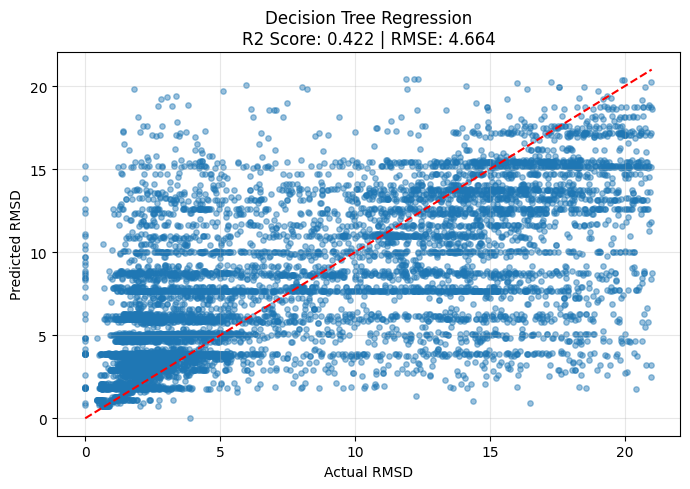

Decision Tree Regression
MAE: 3.3587203592292156
RMSE: 4.663864610310788
R2 Score: 0.422103688977142


In [15]:

model_dt = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

pred_dt = visualize_regression(
    model_dt, "Decision Tree Regression"
)

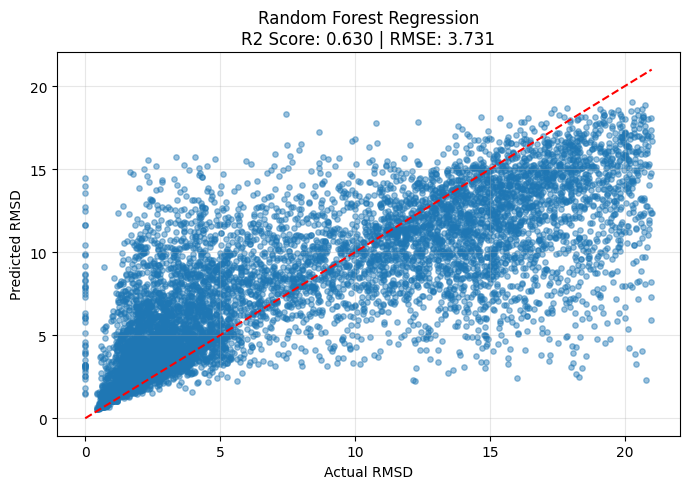

Random Forest Regression
MAE: 2.641256467138763
RMSE: 3.7310468691303935
R2 Score: 0.6301552465026303


In [16]:

model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

pred_rf = visualize_regression(
    model_rf, "Random Forest Regression"
)

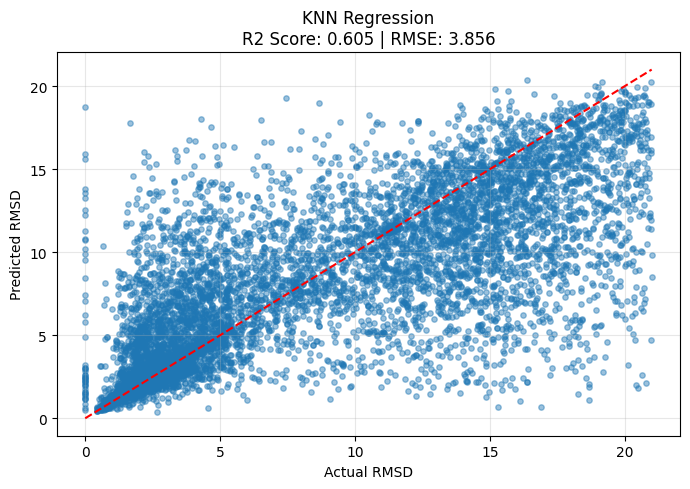

KNN Regression
MAE: 2.453503180372558
RMSE: 3.856174451948703
R2 Score: 0.604932413714079


In [17]:

model_knn = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=5)
)

pred_knn = visualize_regression(
    model_knn, "KNN Regression"
)

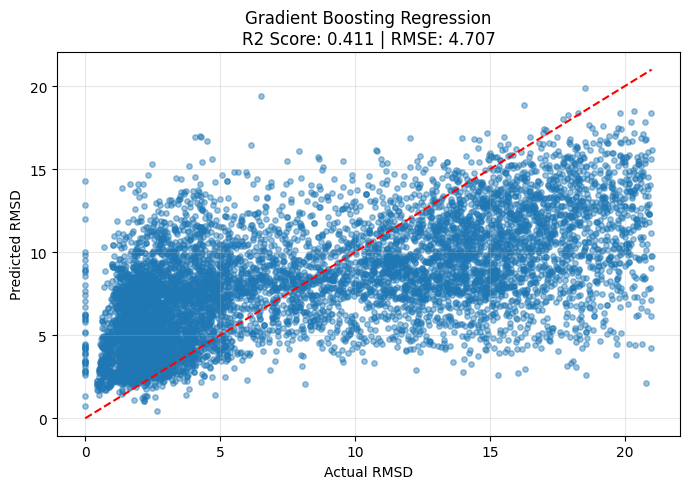

Gradient Boosting Regression
MAE: 3.808623931501684
RMSE: 4.7065024068696095
R2 Score: 0.41148894783383805


In [18]:

model_gb = GradientBoostingRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42
)

pred_gb = visualize_regression(
    model_gb, "Gradient Boosting Regression"
)

In [20]:

from sklearn.svm import LinearSVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_svr = make_pipeline(
    StandardScaler(),
    LinearSVR(max_iter=5000, random_state=42)
)

model_svr.fit(X_train, y_train)
pred_svr = model_svr.predict(X_test)

print("SVR model completed successfully!")

SVR model completed successfully!


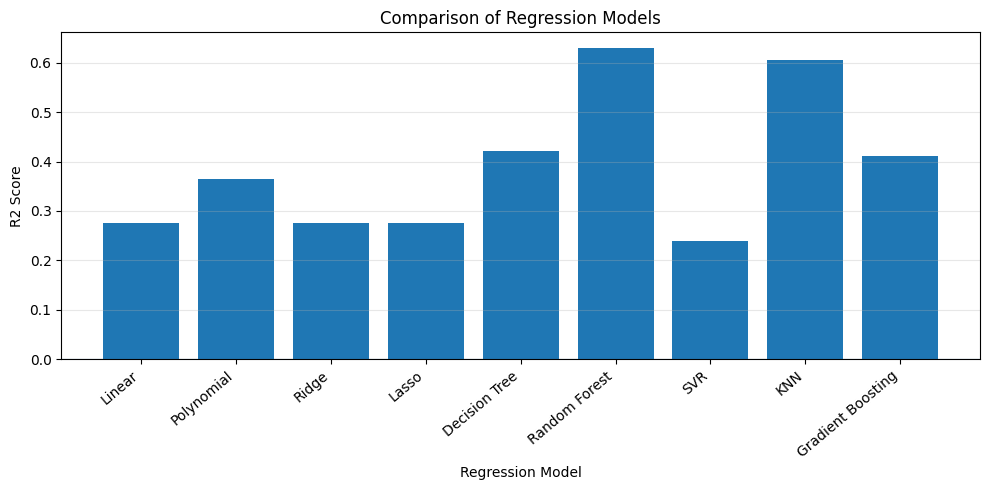

Random Forest: 0.6302
KNN: 0.6049
Decision Tree: 0.4221
Gradient Boosting: 0.4115
Polynomial: 0.3643
Linear: 0.2757
Ridge: 0.2757
Lasso: 0.2748
SVR: 0.2386


In [21]:

models_predictions = {
    "Linear": pred_lr,
    "Polynomial": pred_poly,
    "Ridge": pred_ridge,
    "Lasso": pred_lasso,
    "Decision Tree": pred_dt,
    "Random Forest": pred_rf,
    "SVR": pred_svr,
    "KNN": pred_knn,
    "Gradient Boosting": pred_gb
}

r2_values = {
    name: r2_score(y_test, pred)
    for name, pred in models_predictions.items()
}

plt.figure(figsize=(10, 5))
plt.bar(r2_values.keys(), r2_values.values())
plt.xlabel("Regression Model")
plt.ylabel("R2 Score")
plt.title("Comparison of Regression Models")
plt.xticks(rotation=40, ha="right")
plt.axhline(0, linewidth=0.8)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for name, score in sorted(
    r2_values.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{name}: {score:.4f}")